# Demand Forecasting for Supply Chain Optimization Using Historical Sales Data
## Predictive Analytics Project Using the KDD Methodology

**Objective:** Analyse historical retail sales, identify demand patterns, build and compare machine learning regression models, and evaluate them to support inventory management and supply chain planning.

**Datasets:** 1. Store Item Demand Forecasting  2. Rossmann Store Sales

**Approach:** demand is forecast at the level where stocking decisions are made: each **store x item** series for Dataset 1 and each **store** series for Dataset 2. Errors are therefore in real units (units sold per item per day, or sales per store per day). Lag features are built separately inside each series. Five models are compared and the best one is chosen by validation MAE, not assumed.

# Step 1: Data Selection

In [3]:
import os, zipfile, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Upload: (1) Store Item Demand train.csv   (2) rossmann-store-sales.zip   (3) Rossmann store.csv is inside the zip")
    uploaded = files.upload()
    os.makedirs("/content/rossmann_data", exist_ok=True)
    DEMAND_PATH, ROSS_DIR = None, "/content/rossmann_data"
    for fn in uploaded:
        if fn.lower().endswith(".zip"):
            zipfile.ZipFile(fn).extractall(ROSS_DIR)
        elif fn.lower().endswith(".csv"):
            DEMAND_PATH = fn
else:
    DEMAND_PATH = os.environ["DEMAND_TRAIN"]
    ROSS_DIR = os.environ["ROSS_DIR"]

demand_raw = pd.read_csv(DEMAND_PATH)
rossmann_raw = pd.read_csv(os.path.join(ROSS_DIR, "train.csv"), low_memory=False)
store_info = pd.read_csv(os.path.join(ROSS_DIR, "store.csv"))
print("Dataset 1 (Store Item Demand):", demand_raw.shape)
print("Dataset 2 (Rossmann):", rossmann_raw.shape, "| store.csv:", store_info.shape)
display(demand_raw.head()); display(rossmann_raw.head())

Upload: (1) Store Item Demand train.csv   (2) rossmann-store-sales.zip   (3) Rossmann store.csv is inside the zip


Saving rossmann-store-sales.zip to rossmann-store-sales.zip
Saving train.csv to train.csv
Dataset 1 (Store Item Demand): (913000, 4)
Dataset 2 (Rossmann): (1017209, 9) | store.csv: (1115, 10)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


# Step 2: Data Cleaning
Check missing values, duplicates, data types and invalid sales. Only issues found are handled.

In [4]:
for name, df in [("Dataset 1", demand_raw), ("Dataset 2", rossmann_raw)]:
    print(name, "| missing:", int(df.isnull().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print("\nstore.csv missing values:\n", store_info.isnull().sum()[lambda s: s > 0])
print("\nDataset 1 sales:\n", demand_raw["sales"].describe().round(2))
print("\nRossmann: sales on closed days (Open==0): max =", rossmann_raw.loc[rossmann_raw.Open==0, "Sales"].max(),
      "| closed days =", int((rossmann_raw.Open==0).sum()))
print("Rossmann StateHoliday values:", rossmann_raw["StateHoliday"].unique())

Dataset 1 | missing: 0 | duplicate rows: 0
Dataset 2 | missing: 0 | duplicate rows: 0

store.csv missing values:
 CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

Dataset 1 sales:
 count    913000.00
mean         52.25
std          28.80
min           0.00
25%          30.00
50%          47.00
75%          70.00
max         231.00
Name: sales, dtype: float64

Rossmann: sales on closed days (Open==0): max = 0 | closed days = 172817
Rossmann StateHoliday values: ['0' 'a' 'b' 'c']


In [5]:
demand = demand_raw.copy()
demand["date"] = pd.to_datetime(demand["date"])

ross = rossmann_raw.copy()
ross["Date"] = pd.to_datetime(ross["Date"])
# StateHoliday has mixed types (0 and '0'); map to numeric codes
ross["StateHoliday"] = ross["StateHoliday"].astype(str).map({"0": 0, "a": 1, "b": 2, "c": 3}).fillna(0).astype(int)
ross = ross.merge(store_info, on="Store", how="left")
ross["StoreType"] = ross["StoreType"].map({"a": 0, "b": 1, "c": 2, "d": 3})
ross["Assortment"] = ross["Assortment"].map({"a": 0, "b": 1, "c": 2})
ross["CompetitionDistance"] = ross["CompetitionDistance"].fillna(ross["CompetitionDistance"].median())

# A closed store sells exactly 0 and is known in advance, so it is not a forecasting problem: keep open days only
n_closed = int((ross["Open"] == 0).sum())
print(f"Rossmann: {n_closed:,} closed-store rows are kept only for lag history, not scored")
print("Dataset 1:", demand.shape, "| Dataset 2:", ross.shape)

Rossmann: 172,817 closed-store rows are kept only for lag history, not scored
Dataset 1: (913000, 4) | Dataset 2: (1017209, 18)


# Step 3: Data Transformation
**Key change:** the series is no longer summed across stores and items. Each row stays one store (x item) on one day, so the model sees about 500 separate demand series (Dataset 1) and 1,115 store series (Dataset 2).

Features: calendar variables; lagged sales (1, 7, 14, 28 days, plus 364 days for yearly seasonality in Dataset 1); rolling 7 and 28 day means; Rossmann extras (Promo, SchoolHoliday, StateHoliday, StoreType, Assortment, CompetitionDistance, Promo2); and each series' average sales, computed on training data only. All lags are computed **within each store (x item)**, never across series. The split is chronological: the last 90 days (Dataset 1) and last 42 days (Rossmann) are held out.

In [6]:
def add_features(df, keys, date, target, lags, rolls, open_col=None):
    df = df.sort_values(keys + [date]).reset_index(drop=True)
    g = df.groupby(keys)[target]
    for l in lags:
        df[f"lag_{l}"] = g.shift(l)
    base = df[target] if open_col is None else df[target].where(df[open_col] == 1)
    gb = base.groupby([df[k] for k in keys])
    for w in rolls:
        df[f"roll_mean_{w}"] = gb.transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
    d = df[date].dt
    df["dow"], df["month"], df["day"], df["year"] = d.dayofweek, d.month, d.day, d.year
    df["woy"], df["doy"] = d.isocalendar().week.astype(int), d.dayofyear
    return df

def chrono_split(df, date, days):
    cutoff = df[date].max() - pd.Timedelta(days=days)
    return df[df[date] <= cutoff].copy(), df[df[date] > cutoff].copy()

def add_series_mean(train, valid, keys, target):
    sm = train.groupby(keys)[target].mean().rename("series_mean")
    return train.join(sm, on=keys), valid.join(sm, on=keys)

# ---- Dataset 1: store x item ----
d1 = add_features(demand, ["store", "item"], "date", "sales", lags=[1, 7, 14, 28, 364], rolls=[7, 28])
d1 = d1.dropna(subset=["lag_364"])
d1_train, d1_valid = chrono_split(d1, "date", 90)
d1_train, d1_valid = add_series_mean(d1_train, d1_valid, ["store", "item"], "sales")
F1 = ["store", "item", "dow", "month", "day", "year", "woy", "doy",
      "lag_1", "lag_7", "lag_14", "lag_28", "lag_364", "roll_mean_7", "roll_mean_28", "series_mean"]

# ---- Dataset 2: store ----
d2 = add_features(ross, ["Store"], "Date", "Sales", lags=[1, 7, 14, 21, 28], rolls=[7, 28], open_col="Open")
d2["roll_std_7"] = d2["Sales"].where(d2["Open"] == 1).groupby(d2["Store"]).transform(lambda x: x.shift(1).rolling(7, min_periods=2).std())
d2 = d2.dropna(subset=["lag_28"])
d2 = d2[d2["Open"] == 1]
d2_train, d2_valid = chrono_split(d2, "Date", 42)
d2_train, d2_valid = add_series_mean(d2_train, d2_valid, ["Store"], "Sales")
F2 = ["Store", "StoreType", "Assortment", "CompetitionDistance", "Promo", "Promo2", "SchoolHoliday", "StateHoliday",
      "dow", "month", "day", "year", "woy", "lag_1", "lag_7", "lag_14", "lag_21", "lag_28",
      "roll_mean_7", "roll_mean_28", "roll_std_7", "series_mean"]

print(f"Dataset 1: train {len(d1_train):,} rows | validation {len(d1_valid):,} rows | {len(F1)} features | mean validation sales {d1_valid.sales.mean():.2f}")
print(f"Dataset 2: train {len(d2_train):,} rows | validation {len(d2_valid):,} rows | {len(F2)} features | mean validation sales {d2_valid.Sales.mean():.2f}")

Dataset 1: train 686,000 rows | validation 45,000 rows | 16 features | mean validation sales 54.63
Dataset 2: train 778,563 rows | validation 40,282 rows | 22 features | mean validation sales 6978.64


# Step 4: Data Mining
Five regressors are trained on each dataset with the same features and split: Linear Regression, Decision Tree, Random Forest, Gradient Boosting and LightGBM. They run from the simplest baseline to a modern boosted-tree model, and nothing is assumed about which wins.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=42),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=42),
        "LightGBM": LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1),
    }

def train_and_evaluate(train, valid, features, target, name):
    X, Xv, y, yv = train[features].fillna(0), valid[features].fillna(0), train[target], valid[target]
    rows, preds, fitted = [], {}, {}
    for mname, model in make_models().items():
        model.fit(X, y)
        p = np.clip(model.predict(Xv), 0, None)
        rows.append({"Dataset": name, "Model": mname,
                     "MAE": mean_absolute_error(yv, p),
                     "MSE": mean_squared_error(yv, p),
                     "RMSE": np.sqrt(mean_squared_error(yv, p)),
                     "WAPE (%)": np.abs(yv - p).sum() / yv.sum() * 100,
                     "R2": r2_score(yv, p)})
        preds[mname] = p
        fitted[mname] = model
        print(f"  {name}: {mname} done")
    return pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True), preds, fitted

res1, pred1, fit1 = train_and_evaluate(d1_train, d1_valid, F1, "sales", "Store Item Demand")
res2, pred2, fit2 = train_and_evaluate(d2_train, d2_valid, F2, "Sales", "Rossmann")

  Store Item Demand: Linear Regression done
  Store Item Demand: Decision Tree done
  Store Item Demand: Random Forest done
  Store Item Demand: Gradient Boosting done
  Store Item Demand: LightGBM done
  Rossmann: Linear Regression done
  Rossmann: Decision Tree done
  Rossmann: Random Forest done
  Rossmann: Gradient Boosting done
  Rossmann: LightGBM done


# Step 5: Interpretation and Evaluation

In [8]:
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("DATASET 1: Store Item Demand (per store x item per day), sorted by MAE"); display(res1)
print("DATASET 2: Rossmann (per store per day, open days), sorted by MAE"); display(res2)
best1, best2 = res1.iloc[0], res2.iloc[0]
print("Best model, Dataset 1:", best1["Model"], "| MAE", round(best1["MAE"], 2))
print("Best model, Dataset 2:", best2["Model"], "| MAE", round(best2["MAE"], 2))
pd.concat([res1, res2]).to_csv("model_results.csv", index=False)

DATASET 1: Store Item Demand (per store x item per day), sorted by MAE


,Dataset,Model,MAE,MSE,RMSE,WAPE (%),R2
0,Store Item Demand,LightGBM,5.874,57.914,7.610,10.753,0.928
1,Store Item Demand,Gradient Boosting,5.916,58.802,7.668,10.830,0.927
2,Store Item Demand,Random Forest,6.121,63.537,7.971,11.204,0.921
3,Store Item Demand,Decision Tree,6.532,73.061,8.548,11.956,0.910
4,Store Item Demand,Linear Regression,6.766,77.767,8.819,12.385,0.904


DATASET 2: Rossmann (per store per day, open days), sorted by MAE


,Dataset,Model,MAE,MSE,RMSE,WAPE (%),R2
0,Rossmann,LightGBM,551.714,"645,598.475",803.491,7.906,0.931
1,Rossmann,Gradient Boosting,566.616,"676,144.462",822.280,8.119,0.928
2,Rossmann,Random Forest,569.238,"694,168.451",833.168,8.157,0.926
3,Rossmann,Decision Tree,657.901,"912,438.546",955.216,9.427,0.902
4,Rossmann,Linear Regression,790.370,"1,231,990.368","1,109.951",11.326,0.868


Best model, Dataset 1: LightGBM | MAE 5.87
Best model, Dataset 2: LightGBM | MAE 551.71


In [9]:
# Error scale: is the error believable relative to the size of the numbers?
scale = pd.DataFrame([
    {"Dataset": "Store Item Demand", "Unit forecast": "one item in one store, one day", "Mean actual": d1_valid.sales.mean(),
     "Best model": best1["Model"], "MAE": best1["MAE"], "RMSE": best1["RMSE"], "MAE as % of mean": best1["MAE"] / d1_valid.sales.mean() * 100},
    {"Dataset": "Rossmann", "Unit forecast": "one store, one day", "Mean actual": d2_valid.Sales.mean(),
     "Best model": best2["Model"], "MAE": best2["MAE"], "RMSE": best2["RMSE"], "MAE as % of mean": best2["MAE"] / d2_valid.Sales.mean() * 100},
])
display(scale)
scale.to_csv("error_scale.csv", index=False)

,Dataset,Unit forecast,Mean actual,Best model,MAE,RMSE,MAE as % of mean
0,Store Item Demand,"one item in one store, one day",54.631,LightGBM,5.874,7.610,10.753
1,Rossmann,"one store, one day","6,978.638",LightGBM,551.714,803.491,7.906


### Which features drive the forecast?
Feature importance of the best model (share of total gain). This checks whether the forecast is really driven by past sales, or by something unrelated.

Store Item Demand (LightGBM): past-sales features carry 97.5% of importance; top 5:
lag_364        49.900
roll_mean_7    24.800
lag_7          13.000
roll_mean_28    5.700
lag_14          2.100 

Rossmann (LightGBM): past-sales features carry 85.9% of importance; top 5:
lag_14        47.500
roll_mean_7   10.400
lag_28         9.800
Promo          6.600
series_mean    6.000 



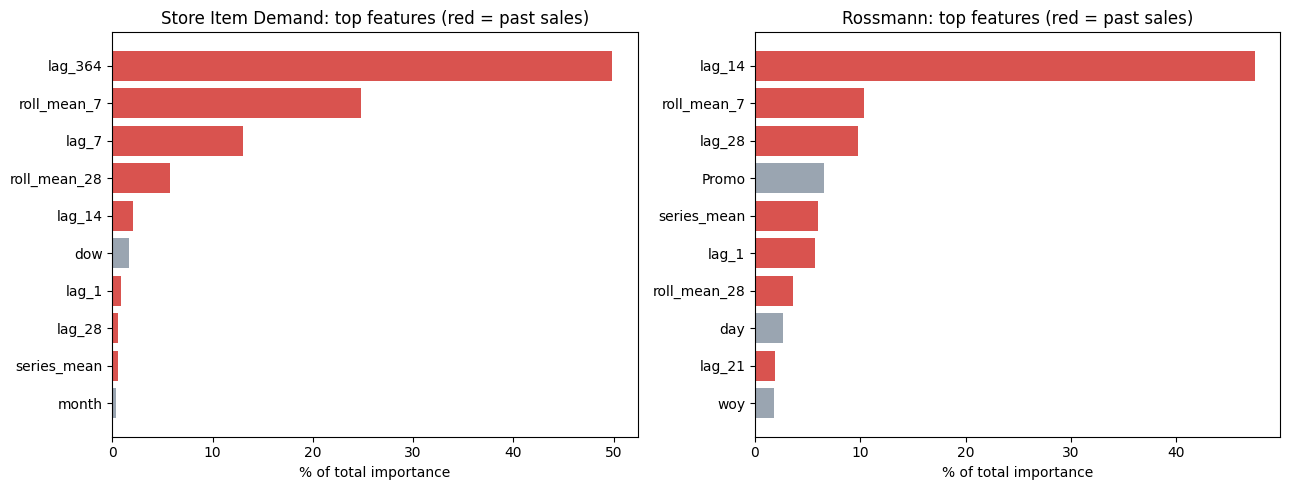

In [10]:
def importance_table(model, features):
    if hasattr(model, "booster_"):
        v = model.booster_.feature_importance(importance_type="gain")
    else:
        v = model.feature_importances_
    return pd.Series(v / v.sum() * 100, index=features).sort_values(ascending=False)

past_sales = lambda f: f.startswith("lag_") or f.startswith("roll_") or f == "series_mean"
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, best, fitted, feats in [(axes[0], "Store Item Demand", best1, fit1, F1), (axes[1], "Rossmann", best2, fit2, F2)]:
    imp = importance_table(fitted[best["Model"]], feats)
    share = imp[[f for f in imp.index if past_sales(f)]].sum()
    print(f"{name} ({best['Model']}): past-sales features carry {share:.1f}% of importance; top 5:")
    print(imp.head(5).round(1).to_string(), "\n")
    top = imp.head(10)[::-1]
    ax.barh(top.index, top.values, color=["#d9534f" if past_sales(f) else "#9aa5b1" for f in top.index])
    ax.set_title(f"{name}: top features (red = past sales)"); ax.set_xlabel("% of total importance")
plt.tight_layout(); plt.savefig("plots/feature_importance.png", dpi=160); plt.show()

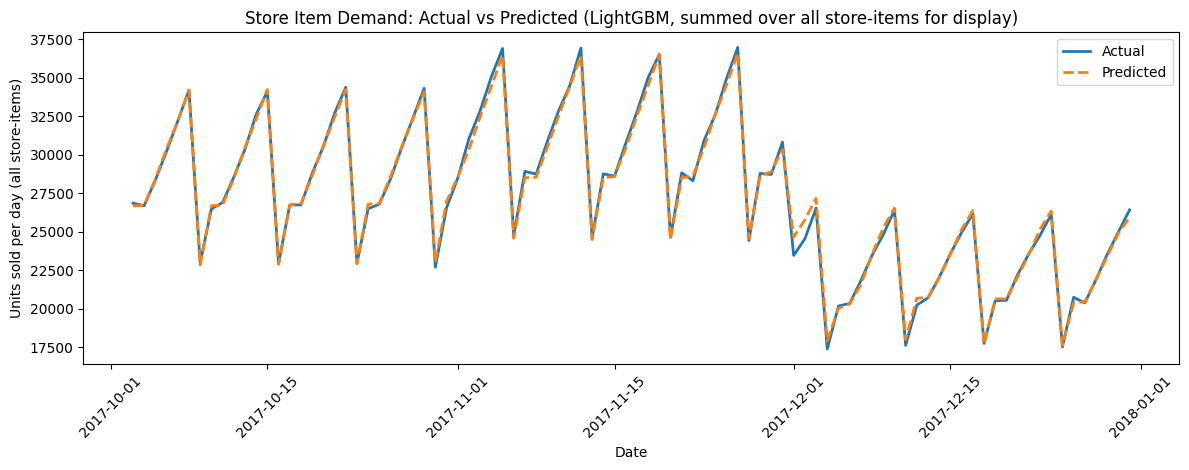

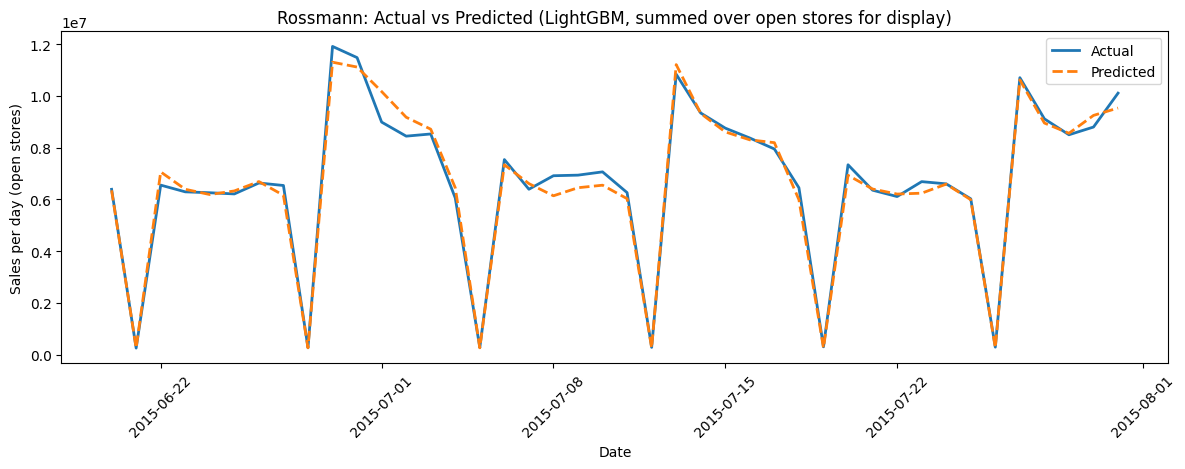

In [11]:
def plot_actual_vs_pred(valid, date, target, pred, title, fname, ylabel):
    tmp = valid[[date, target]].copy(); tmp["pred"] = pred
    daily = tmp.groupby(date)[[target, "pred"]].sum()
    fig, ax = plt.subplots(figsize=(12, 4.8))
    ax.plot(daily.index, daily[target], label="Actual", linewidth=2)
    ax.plot(daily.index, daily["pred"], label="Predicted", linewidth=2, linestyle="--")
    ax.set_title(title); ax.set_xlabel("Date"); ax.set_ylabel(ylabel); ax.legend()
    plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(f"plots/{fname}", dpi=160); plt.show()

# Metrics are computed per row (store x item / store). The chart only sums rows by date so the shape is easy to see.
plot_actual_vs_pred(d1_valid, "date", "sales", pred1[best1["Model"]],
    f"Store Item Demand: Actual vs Predicted ({best1['Model']}, summed over all store-items for display)", "d1_actual_vs_pred.png", "Units sold per day (all store-items)")
plot_actual_vs_pred(d2_valid, "Date", "Sales", pred2[best2["Model"]],
    f"Rossmann: Actual vs Predicted ({best2['Model']}, summed over open stores for display)", "d2_actual_vs_pred.png", "Sales per day (open stores)")

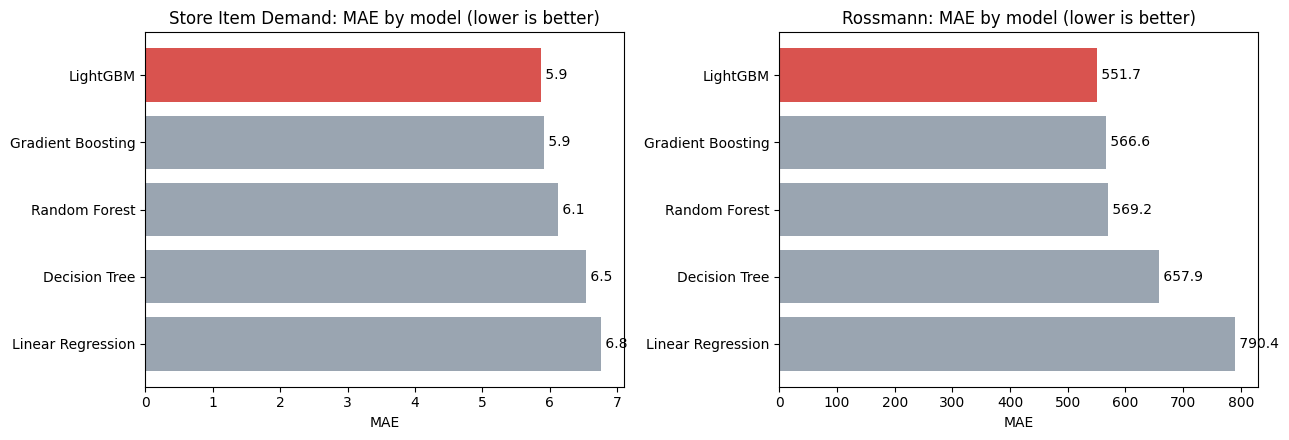

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, res, title in [(axes[0], res1, "Store Item Demand"), (axes[1], res2, "Rossmann")]:
    r = res.sort_values("MAE", ascending=False)
    ax.barh(r["Model"], r["MAE"], color=["#d9534f" if m == res.iloc[0]["Model"] else "#9aa5b1" for m in r["Model"]])
    ax.set_title(f"{title}: MAE by model (lower is better)"); ax.set_xlabel("MAE")
    for i, v in enumerate(r["MAE"]): ax.text(v, i, f" {v:,.1f}", va="center")
plt.tight_layout(); plt.savefig("plots/model_comparison_mae.png", dpi=160); plt.show()

# Step 6: Knowledge Presentation

In [13]:
from IPython.display import Markdown
def line(res, label):
    b, w = res.iloc[0], res.iloc[-1]
    return (f"**{label}:** best model is **{b['Model']}** (MAE {b['MAE']:,.2f}, RMSE {b['RMSE']:,.2f}, WAPE {b['WAPE (%)']:.2f}%, R2 {b['R2']:.3f}); "
            f"weakest is {w['Model']} (MAE {w['MAE']:,.2f}, R2 {w['R2']:.3f}). "
            f"The best model's MAE is {(1 - b['MAE']/w['MAE'])*100:.1f}% lower than the weakest.")
display(Markdown("### Conclusion\n\n" + line(res1, "Store Item Demand") + "\n\n" + line(res2, "Rossmann") + f"""

**Reading the errors.** Dataset 1 is forecast per item per store (mean about {d1_valid.sales.mean():.0f} units a day), so a MAE of {best1['MAE']:.1f} units is {best1['MAE']/d1_valid.sales.mean()*100:.1f}% of the typical value. Dataset 2 is forecast per store (mean about {d2_valid.Sales.mean():,.0f} a day), so a MAE of {best2['MAE']:,.0f} is {best2['MAE']/d2_valid.Sales.mean()*100:.1f}% of the typical value. Rossmann store-day sales are in the thousands, so its error is naturally in the hundreds; WAPE and MAE as a percentage of the mean are the fair way to compare the two datasets.

**Limits.** Forecasts are one day ahead using actual lagged sales, with one chronological split and fixed hyperparameters. A longer horizon, rolling-window validation and hyperparameter tuning are the next steps."""))

### Conclusion

**Store Item Demand:** best model is **LightGBM** (MAE 5.87, RMSE 7.61, WAPE 10.75%, R2 0.928); weakest is Linear Regression (MAE 6.77, R2 0.904). The best model's MAE is 13.2% lower than the weakest.

**Rossmann:** best model is **LightGBM** (MAE 551.71, RMSE 803.49, WAPE 7.91%, R2 0.931); weakest is Linear Regression (MAE 790.37, R2 0.868). The best model's MAE is 30.2% lower than the weakest.

**Reading the errors.** Dataset 1 is forecast per item per store (mean about 55 units a day), so a MAE of 5.9 units is 10.8% of the typical value. Dataset 2 is forecast per store (mean about 6,979 a day), so a MAE of 552 is 7.9% of the typical value. Rossmann store-day sales are in the thousands, so its error is naturally in the hundreds; WAPE and MAE as a percentage of the mean are the fair way to compare the two datasets.

**Limits.** Forecasts are one day ahead using actual lagged sales, with one chronological split and fixed hyperparameters. A longer horizon, rolling-window validation and hyperparameter tuning are the next steps.